# Backpropagation vs Predictive Coding on MNIST
Both networks come from the `src/` package. Run the cells top to bottom.

**Architecture:** 784 → 128 → 64 → 10 (tanh hidden, linear output), MSE on one-hot labels, identical initial weights.

> Data: put `mnist.npz` (Keras format) in `data/`, or run with internet so scikit-learn can download it.

In [1]:
import sys, numpy as np
sys.path.append("..")            # make `src` importable from notebooks/
%matplotlib inline
from src import (load_mnist, BPNet, PCNet, train, accuracy, pc_vs_bp_gradient_similarity,
                 plot_samples, plot_training, plot_layer_energy, plot_predictions)

## 1. Data (MNIST)
Use a subset for speed; set `N_TRAIN = None` for all 60,000 training images.

train (5000, 784) | test (1000, 784) | sizes [784, 128, 64, 10]


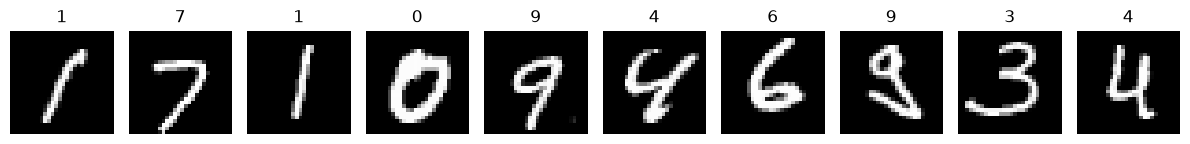

In [3]:
N_TRAIN, N_TEST = 5000, 1000
EPOCHS, LR, BATCH = 20, 0.02, 100   # LR tuned for stability with 784 inputs

ds = load_mnist(n_train=N_TRAIN, n_test=N_TEST)
Xtr, ytr, Ytr, Xte, yte = ds.Xtr, ds.ytr, ds.Ytr, ds.Xte, ds.yte
sizes = [ds.n_in, 128, 64, ds.n_out]
print("train", Xtr.shape, "| test", Xte.shape, "| sizes", sizes)
plot_samples(ds);